# CS 6220 – Homework 1: Iris Classification Pipeline
Tests my Python + Jupyter + scikit-learn setup with the classic Iris dataset.

**Structure**
1. Load data
2. Explore / scatterplots (optional)
3. Train/test split (80/20)
4. scikit-learn `Pipeline` (scaler + logistic regression), timed training and testing
5. Accuracy + confusion matrix
6. Hyperparameter exploration (optional)

## 1. Imports

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

Matplotlib is building the font cache; this may take a moment.


## 2. Load the data
The UCI file `iris.data` has no header row, so I supply the column names. If `iris.data` is not in the
project folder, the cell tries to download it from UCI, and falls back to scikit-learn's bundled copy.

In [2]:
COLUMNS = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

def load_iris_df():
    """Return the Iris dataset as a DataFrame with the 4 features plus a 'class' column."""
    for source in ("iris.data", UCI_URL):
        try:
            return pd.read_csv(source, header=None, names=COLUMNS)
        except Exception:
            continue
    from sklearn.datasets import load_iris   # fallback: same data, bundled with scikit-learn
    d = load_iris(as_frame=True)
    df = d.frame.drop(columns="target")
    df.columns = COLUMNS[:4]
    df["class"] = d.target_names[d.target]
    return df

df = load_iris_df()
print(df.shape)
df.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Quick sanity checks: class balance and missing values
print(df["class"].value_counts())
print("Missing values:", df.isna().sum().sum())

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Missing values: 0


## 3. Scatterplots (optional)

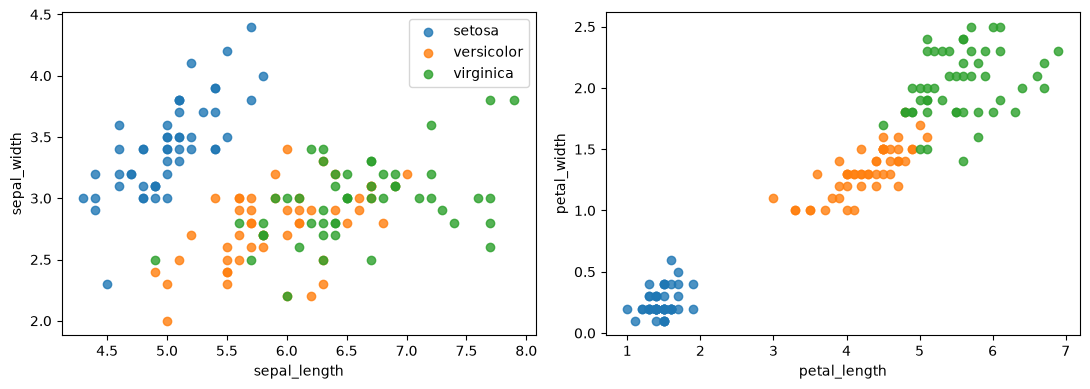

In [4]:
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
df["class"] = df["class"].str.replace("Iris-", "", regex=False)   # UCI labels look like 'Iris-setosa'

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (x, y) in zip(axes, [("sepal_length", "sepal_width"), ("petal_length", "petal_width")]):
    for cls, g in df.groupby("class"):
        ax.scatter(g[x], g[y], label=cls, c=colors[cls], alpha=0.8)
    ax.set_xlabel(x); ax.set_ylabel(y)
axes[0].legend()
plt.tight_layout(); plt.show()

## 4. Train/test split (80/20)
`stratify=y` keeps the class proportions equal in both sets; `random_state` makes it reproducible.

In [5]:
X = df.drop(columns="class")
y = df["class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape)

train: (120, 4)  test: (30, 4)


## 5. Build the Pipeline
A `Pipeline` chains steps so the scaler is fit on training data only, then applied to test data
automatically (no data leakage).

In [6]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=200)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-pe

## 6. Train and time it

In [7]:
t0 = time.perf_counter()
pipe.fit(X_train, y_train)
train_time = time.perf_counter() - t0
print(f"Training time: {train_time*1000:.3f} ms")

Training time: 9.490 ms


## 7. Test and time it

In [8]:
t0 = time.perf_counter()
y_pred = pipe.predict(X_test)
test_time = time.perf_counter() - t0
acc = accuracy_score(y_test, y_pred)
print(f"Testing time:  {test_time*1000:.3f} ms")
print(f"Test accuracy: {acc:.4f} ({acc*100:.2f}%)")

Testing time:  0.935 ms
Test accuracy: 0.9333 (93.33%)


## 8. Confusion matrix (optional)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


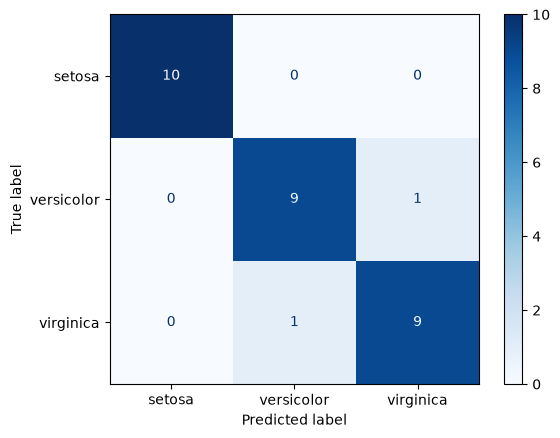

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=pipe.classes_)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=pipe.classes_).plot(cmap="Blues")
plt.show()

## 9. Hyperparameter exploration (optional)
Logistic regression: vary regularization strength `C` (smaller = stronger regularization).
Also compare k-nearest-neighbors with different `k`.
Note that with only 30 test samples, one mistake changes accuracy by about 3.3 points.

In [10]:
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    p = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=500))])
    p.fit(X_train, y_train)
    rows.append(("LogReg", f"C={C}", accuracy_score(y_test, p.predict(X_test))))
for k in [1, 3, 5, 9, 15, 25]:
    p = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    p.fit(X_train, y_train)
    rows.append(("kNN", f"k={k}", accuracy_score(y_test, p.predict(X_test))))
pd.DataFrame(rows, columns=["model", "setting", "test_accuracy"])

,model,setting,test_accuracy
0,LogReg,C=0.001,0.766667
1,LogReg,C=0.01,0.800000
2,LogReg,C=0.1,0.866667
3,LogReg,C=1,0.933333
4,LogReg,C=10,1.000000
5,LogReg,C=100,1.000000
6,kNN,k=1,0.966667
7,kNN,k=3,0.933333
8,kNN,k=5,0.933333
9,kNN,k=9,0.966667


## Summary
- Model: StandardScaler + LogisticRegression (scikit-learn Pipeline), 80/20 stratified split
- Results are printed above (training time, testing time, accuracy).
- Very small regularization values underfit; moderate and large values reach high accuracy on this easy dataset.